# Does the effect exist? Signal exploration on the real Lynx data

**Question for every family: is there a real, stable, explainable effect in the data, before anyone writes a backtest?**

Families checked: trend, short-term reversion, relative value (twin assets, cross-moon spreads), cross-asset lead-lag, macro (GDP and CPI per moon), price bars (OHLC). Plus the data quality and structure facts every model needs.

### How to read the numbers

- **IC (information coefficient)** = correlation between a signal known at the close of day T and the asset's move that we can actually earn: from the close of T+1 to the close of T+1+h. That matches Lynx's rule: a position set at T earns P(T+2) − P(T+1) first. Moves are divided by the asset's own volatility, so assets are comparable.
- **Size guide.** Daily data is noisy: IC 0.02 is already meaningful if it is stable, 0.05 is strong, 0.10+ is very strong for a 20–60 day horizon.
- **Significance.** With overlapping h-day windows there are only about N/h independent observations, so one asset's t-stat ≈ IC · √(N/h). For h = 60 over 22 years that is about √95 ≈ 10: IC 0.2 → t ≈ 2 per asset.
- **Stability test.** Every key number is also computed in three eras (1995–2002, 2002–2009, 2009–2016, the same split as Jaakko's tables). **An effect counts only if it has the same sign in all three eras** and in most assets of its group.
- **Uncentered IC, causal features.** A normal correlation subtracts full-sample averages, which quietly uses the future and throws away drift that the P&L does earn. Here IC = Σ(signal·move) / √(Σsignal² · Σmove²), which is exactly what a position earns. Macro features are measured against their own **trailing** 3-year average, never the full-sample one. This matters: with a normal correlation a "GDP → stocks" effect shows up that disappears once it's done causally (section 8).
- **Many tests = some lucky ones.** Where a grid has hundreds of cells, there's a placebo or era-repeat check next to it.

Run time: about a minute. Everything uses only `data/` from the repo.

### The answer, in five lines
1. **Inflation predicts bonds and stocks** of the same moon, in all five moons and all three eras. It's the planted macro edge and the main new signal (section 8).
2. **Trend is real in every asset class but fading**: about zero for stocks, commodities and FX in 2009–16 (section 5).
3. **Trend and inflation are uncorrelated**: an untuned blend scores about 1.0 adjusted Sharpe, against 0.87 for trend alone, and holds up in the weak 2009–16 era (section 10).
4. **Short-term reversion, lead-lag, OHLC features and GDP are dead ends** here (sections 5, 7, 8, 9).
5. **Twin commodity spreads** are a small optional extra: two of three pairs revert, one trends (section 6).

In [1]:
import warnings, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "lynx_materials")]
import polars as pl
import evaluation as ev

pd.set_option("display.width", 220, "display.max_columns", 40, "display.precision", 3)

# palette: categorical slots in fixed order, diverging blue <-> gray <-> red
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.6, "font.size": 9, "legend.frameon": False, "figure.dpi": 110,
})

def heat(ax, df, title, vmax=None, fmt="{:.2f}", annot=True, fontsize=7):
    v = df.values.astype(float)
    vmax = vmax or np.nanmax(np.abs(v))
    im = ax.imshow(v, cmap=DIV, vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(df.shape[1]), df.columns, rotation=90)
    ax.set_yticks(range(df.shape[0]), df.index)
    ax.grid(False)
    if annot:
        for i in range(v.shape[0]):
            for j in range(v.shape[1]):
                if np.isfinite(v[i, j]):
                    ax.text(j, i, fmt.format(v[i, j]), ha="center", va="center", fontsize=fontsize,
                            color=INK if abs(v[i, j]) < 0.6 * vmax else "white")
    ax.set_title(title)
    return im

## 1. What is in the data

In [2]:
px = pd.read_csv(ROOT / "data/close_prices_insample.csv", parse_dates=["AsOfDate"], index_col=0)
macro = pd.read_csv(ROOT / "data/macro_data_insample.csv", parse_dates=["AsOfDate"], index_col=0)
bars = pd.read_csv(ROOT / "data/prices_insample.csv", parse_dates=["AsOfDate"], index_col=0)

MOONS = ["ganymede", "io", "titan", "callisto", "europa"]
CLASSES = ["bonds", "stocks", "titan_fx"]
GROUP = {}
for a in px:
    cls = next((k for k in CLASSES if a.endswith(k)), None)
    GROUP[a] = {"bonds": "bonds", "stocks": "stocks", "titan_fx": "fx"}.get(cls, "commodities")
GROUPS = {g: [a for a in px if GROUP[a] == g] for g in ["bonds", "stocks", "fx", "commodities"]}
ORDER = sum(GROUPS.values(), [])

inv = pd.DataFrame({
    "file": ["close_prices_insample.csv", "prices_insample.csv", "macro_data_insample.csv"],
    "rows": [len(px), len(bars), len(macro)],
    "columns": [px.shape[1], bars.shape[1], macro.shape[1]],
    "first": [px.index[0].date(), bars.index[0].date(), macro.index[0].date()],
    "last": [px.index[-1].date(), bars.index[-1].date(), macro.index[-1].date()],
    "calendar": ["weekdays", "weekdays", "every calendar day"],
}).set_index("file")
display(inv)
display(pd.Series({g: ", ".join(v) for g, v in GROUPS.items()}, name="assets").to_frame())
print("closes in both price files identical:",
      np.allclose(bars[[f"{a}|Close" for a in px]].values, px.values, equal_nan=True))
print("missing closes:", int(px.isna().sum().sum()), "| missing OHLC fields:", int(bars.isna().sum().sum()),
      "| prices <= 0:", int((px <= 0).sum().sum()))

,rows,columns,first,last,calendar
file,,,,,
close_prices_insample.csv,5702,27,1995-01-02,2016-12-30,weekdays
prices_insample.csv,5702,108,1995-01-02,2016-12-30,weekdays
macro_data_insample.csv,8036,10,1995-01-01,2016-12-31,every calendar day


,assets
bonds,"ganymede_bonds, io_bonds, titan_bonds, callist..."
stocks,"ganymede_stocks, io_stocks, titan_stocks, call..."
fx,"ganymede_titan_fx, io_titan_fx, callisto_titan..."
commodities,"helium3, water, titanium, antimatter, aerogel,..."


closes in both price files identical: True
missing closes: 0 | missing OHLC fields: 1067 | prices <= 0: 0


**Structure.** 5 moons × (bonds, stocks, FX vs titan) minus titan's own FX = 14 financial assets, plus 13 commodities = **27 assets**. Macro is **GDP and CPI per moon**, one value per calendar day. All prices start near 1.0 (indexed). No missing closes, no negative prices.

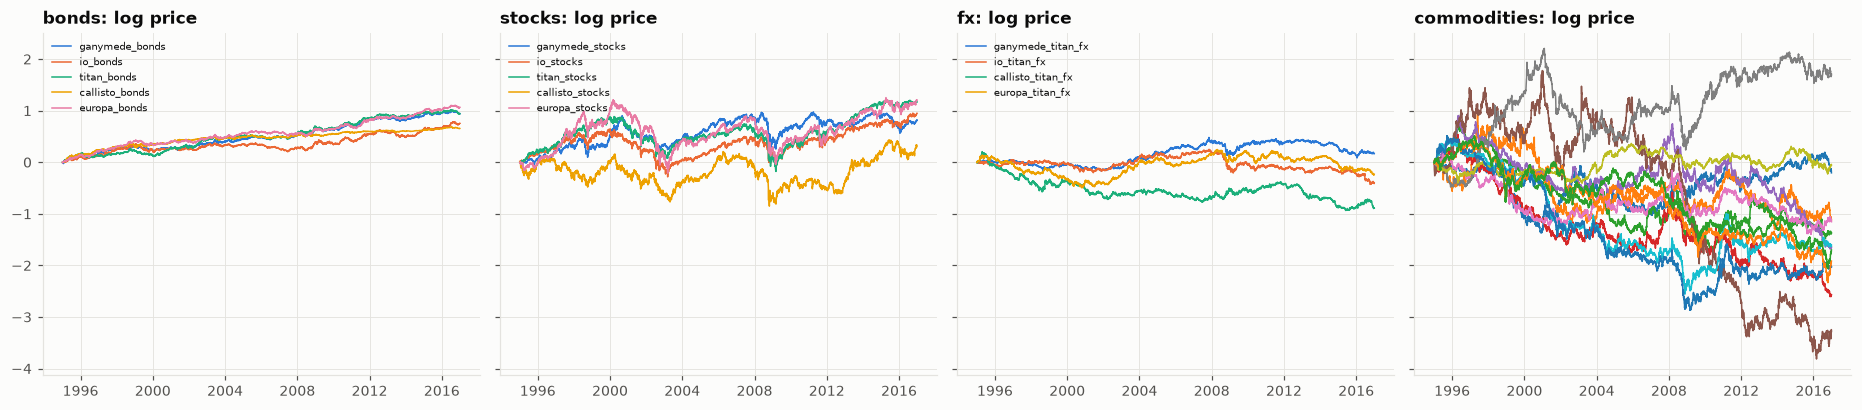

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, (g, cols) in zip(axes, GROUPS.items()):
    for i, a in enumerate(cols):
        ax.plot(px.index, np.log(px[a]), lw=1.0, color=C[i % len(C)] if len(cols) <= 8 else None, label=a)
    ax.set_title(f"{g}: log price")
    if len(cols) <= 8:
        ax.legend(fontsize=6.5, loc="upper left")
fig.tight_layout(); plt.show()

## 2. Data quality: holidays, jumps, fat tails

In [4]:
d = px.diff()
vol = np.sqrt((d ** 2).ewm(span=60, min_periods=30).mean())
z = (d / vol.shift(1)).replace([np.inf, -np.inf], np.nan)          # daily move in units of yesterday's vol
zero = d == 0

cal = {}
for mo in MOONS:
    cols = [a for a in px if a.startswith(mo + "_")]
    cal[mo] = [int(zero[cols].all(axis=1).sum()), int(zero[cols].any(axis=1).sum())]
cal["commodities"] = [int(zero[GROUPS["commodities"]].all(axis=1).sum()), int(zero[GROUPS["commodities"]].any(axis=1).sum())]
cal = pd.DataFrame(cal, index=["days all assets flat", "days any asset flat"]).T
same = (zero[[a for a in px if a.startswith("titan_")]].all(axis=1) == zero[GROUPS["commodities"]].all(axis=1)).mean()
display(cal)
print(f"titan holidays and commodity holidays fall on the same day {same:.1%} of the time")

q = pd.DataFrame({"group": pd.Series(GROUP), "daily skew": z.skew(), "excess kurtosis": z.kurt(),
                  ">6 sigma days": (z.abs() > 6).sum(), "worst day (sigma)": z.min(), "best day (sigma)": z.max()})
display(q.loc[ORDER].round(2).style.background_gradient(cmap=DIV, subset=["daily skew"], vmin=-0.8, vmax=0.8)
        .format(precision=2))

,days all assets flat,days any asset flat
ganymede,80,333
io,49,176
titan,226,235
callisto,37,396
europa,55,322
commodities,226,277


titan holidays and commodity holidays fall on the same day 100.0% of the time


,group,daily skew,excess kurtosis,>6 sigma days,worst day (sigma),best day (sigma)
ganymede_bonds,bonds,-0.18,1.13,0,-5.13,4.76
io_bonds,bonds,0.01,1.41,1,-4.72,7.29
titan_bonds,bonds,-0.17,1.36,0,-5.41,5.33
callisto_bonds,bonds,-0.45,5.36,4,-10.09,8.40
europa_bonds,bonds,-0.13,1.06,0,-5.01,5.17
ganymede_stocks,stocks,-0.48,1.92,1,-8.95,4.16
io_stocks,stocks,-0.24,0.82,0,-5.16,4.82
titan_stocks,stocks,-0.38,2.01,2,-6.90,6.49
callisto_stocks,stocks,-0.28,1.94,1,-6.82,4.90
europa_stocks,stocks,-0.28,1.17,1,-6.36,4.86


**Takeaways**
- **Each moon has its own holiday calendar**, and the commodities trade on **titan's** calendar. On a holiday the price is repeated, so the next day carries two days of move. That creates fake same-day correlation gaps between moons and fake lead-lag (checked in section 7).
- **No roll-gap style jumps.** Only a handful of >6σ days per asset over 22 years, so Jaakko's jump clip rarely bites here; it's harmless to keep.
- **Stocks and `callisto_bonds` have negative skew** (crash risk), several commodities positive skew. The adjusted Sharpe punishes negative skew, so long-only exposure to stocks is costly in the score; trend tends to cut it.
- **`ultrapure_silicon` has fat tails (kurtosis ~10)**: it can dominate portfolio kurtosis. Worth a smaller risk budget or a cap.

## 3. Structure: how many independent bets are there?

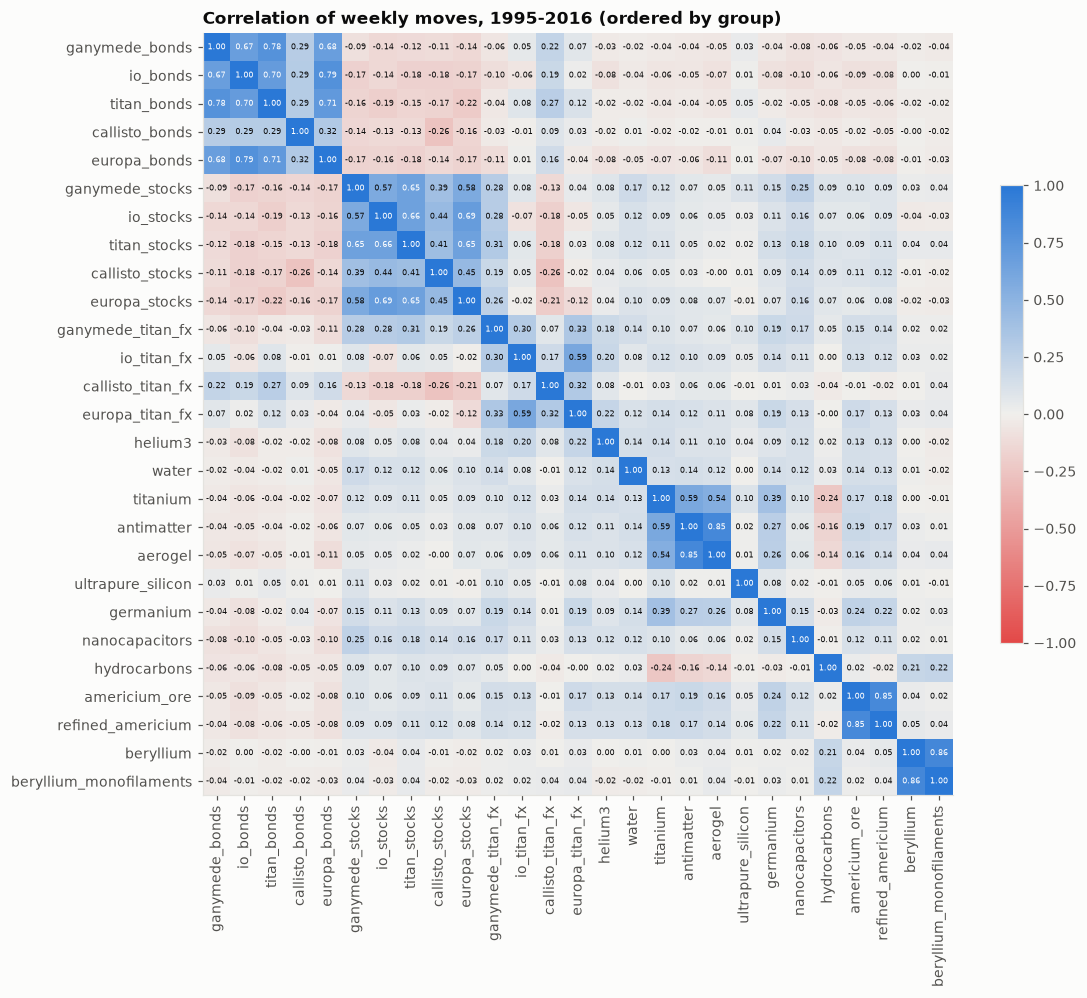

,,weekly corr
io_stocks,europa_stocks,0.693
io_bonds,titan_bonds,0.701
titan_bonds,europa_bonds,0.711
ganymede_bonds,titan_bonds,0.780
io_bonds,europa_bonds,0.789
americium_ore,refined_americium,0.850
antimatter,aerogel,0.852
beryllium,beryllium_monofilaments,0.861
callisto_bonds,callisto_stocks,-0.263
callisto_stocks,callisto_titan_fx,-0.263


effective number of independent assets: 13.2 of 27 | first component explains 17%


In [5]:
wk = px.resample("W-FRI").last().diff()           # weekly moves: robust to the holiday mismatches
wk = wk / wk.rolling(52, min_periods=20).std().shift(1)
cw = wk.corr().loc[ORDER, ORDER]

fig, ax = plt.subplots(figsize=(11, 9))
im = heat(ax, cw, "Correlation of weekly moves, 1995-2016 (ordered by group)", vmax=1, fontsize=5.5)
fig.colorbar(im, ax=ax, shrink=0.6); plt.show()

eig = np.linalg.eigvalsh(cw.fillna(0).values)[::-1]
n_eff = eig.sum() ** 2 / (eig ** 2).sum()
top = cw.where(np.triu(np.ones(cw.shape, bool), 1)).stack().dropna()
display(pd.concat([top.sort_values().tail(8), top.sort_values().head(6)]).rename("weekly corr").to_frame())
print(f"effective number of independent assets: {n_eff:.1f} of 27 | first component explains {eig[0] / eig.sum():.0%}")

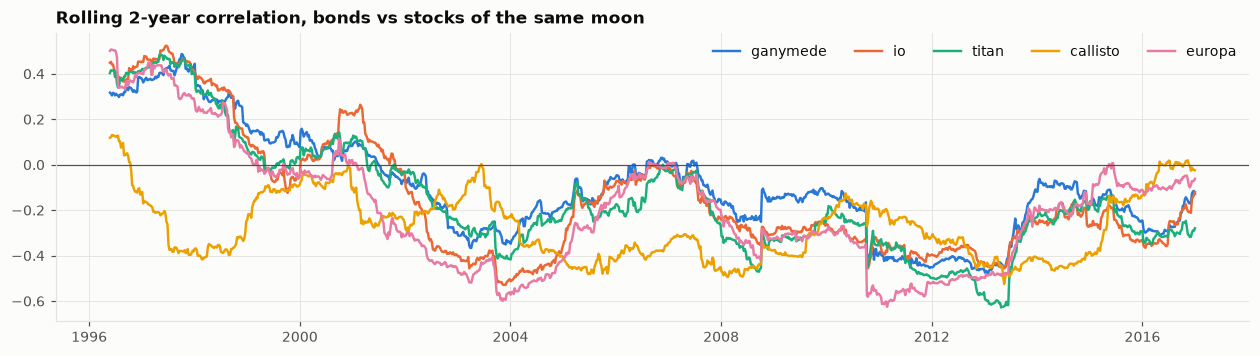

In [6]:
# bond-stock correlation per moon over time: does the hedge flip?
fig, ax = plt.subplots(figsize=(14, 3.4))
for i, mo in enumerate(MOONS):
    r = wk[f"{mo}_bonds"].rolling(104, min_periods=52).corr(wk[f"{mo}_stocks"])
    ax.plot(r.index, r, color=C[i], label=mo)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_title("Rolling 2-year correlation, bonds vs stocks of the same moon"); ax.legend(ncol=5)
plt.show()

**Takeaways**
- **About 13 independent bets out of 27.** The first common factor explains only 17%, so there's no single "market" driving everything, but there are clusters.
- **Bonds move together across moons** (weekly correlation 0.5–0.8): one shared interest-rate factor. Five bond positions are closer to two or three bets.
- **Three twin commodity pairs** move almost one-for-one (~0.85): `antimatter`/`aerogel`, `americium_ore`/`refined_americium`, `beryllium`/`beryllium_monofilaments`.
- **Bonds vs stocks of the same moon are negatively correlated** (the classic hedge), most clearly on callisto.
- **For risk:** twins should share one risk budget and the bond block needs a cap, otherwise the model bets several times on the same thing. Jaakko's covariance-based book scaling already handles this partly.

## 4. Volatility: does it cluster, and does sizing matter?

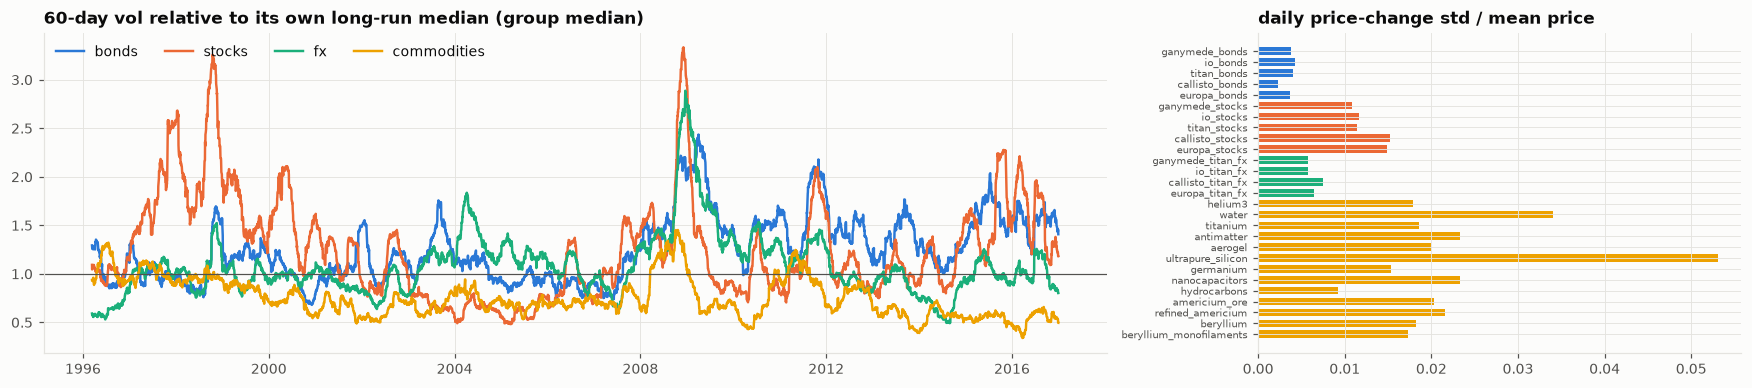

autocorrelation of |daily move|, mean over assets: {1: 0.013, 5: 0.023, 20: 0.012, 60: -0.001}
ratio of most to least volatile asset (price-change std): 22.2


In [7]:
rv = d.pow(2).rolling(60).mean().pow(0.5)
rel = rv / rv.expanding(250).median()
acf = pd.DataFrame({lag: [z[a].abs().autocorr(lag) for a in ORDER] for lag in [1, 5, 20, 60]}, index=ORDER)

fig, axes = plt.subplots(1, 2, figsize=(16, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
for i, (g, cols) in enumerate(GROUPS.items()):
    axes[0].plot(rel.index, rel[cols].median(axis=1), color=C[i], label=g)
axes[0].axhline(1, color=INK2, lw=0.8)
axes[0].set_title("60-day vol relative to its own long-run median (group median)"); axes[0].legend(ncol=4)
vol_level = (d.std() / px.mean()).loc[ORDER]
axes[1].barh(range(27), vol_level.values, color=[C[list(GROUPS).index(GROUP[a])] for a in ORDER], height=0.7)
axes[1].set_yticks(range(27), ORDER, fontsize=6.5); axes[1].invert_yaxis()
axes[1].set_title("daily price-change std / mean price")
fig.tight_layout(); plt.show()

print("autocorrelation of |daily move|, mean over assets:", acf.mean().round(3).to_dict())
print("ratio of most to least volatile asset (price-change std):", round(d.std().max() / d.std().min(), 1))

**Takeaways**
- **Volatility barely clusters** (|move| autocorrelation ≈ 0.01, real markets are 0.2–0.3). Vol is close to constant per asset, apart from slow drifts. So **volatility timing/targeting will add little**; a long, stable vol estimate is enough and avoids noise in sizing.
- **Vol levels differ a lot across assets**, so **inverse-vol sizing still matters**. Without it a few assets carry all the risk.

## 5. Own-asset predictability: trend or reversion?

Signal: the asset's own move over the last *k* days (in vol units). Target: the earnable move over the next *h* days. Positive IC = trend, negative = reversion.

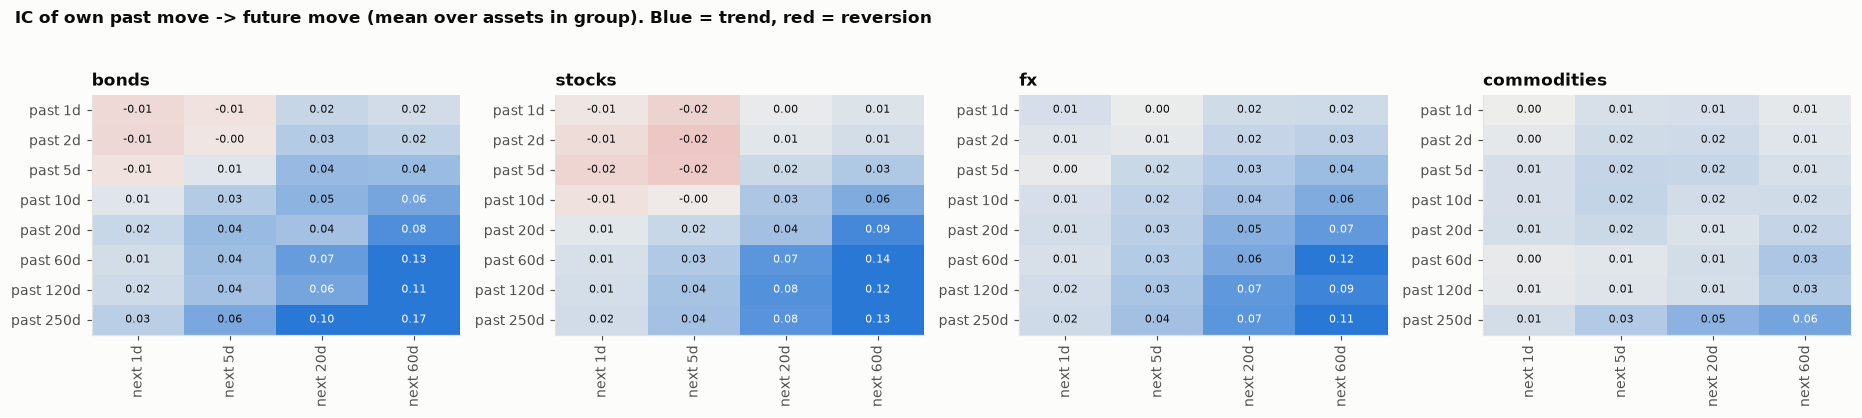

In [8]:
LOOKBACKS = [1, 2, 5, 10, 20, 60, 120, 250]
HORIZONS = [1, 5, 20, 60]
ERAS = {"1995-02": ("1995", "2001"), "2002-09": ("2002", "2008"), "2009-16": ("2009", "2016")}

def fwd(h):  # earnable move: close T+1 -> close T+1+h, in units of vol known at T
    return (px.shift(-(1 + h)) - px.shift(-1)) / (vol * np.sqrt(h))

FWD = {h: fwd(h) for h in [1, 5, 10, 20, 60]}

def uic(S, F):
    # uncentered correlation per column: sum(s*f) / sqrt(sum(s^2) sum(f^2)).
    # This is the correlation a position actually earns (P&L = position x move). A centered correlation
    # subtracts full-sample means, which silently uses the future and hides drift the P&L does see.
    m = S.notna() & F.notna()
    S0, F0 = S.where(m, 0.0), F.where(m, 0.0)
    return (S0 * F0).sum() / np.sqrt((S0 ** 2).sum() * (F0 ** 2).sum())

def us(s, f):  # same, for two series
    return uic(s.rename("x").to_frame(), f.rename("x").to_frame())["x"]

def ic(sig, h, start=None, end=None, cols=None):
    cols = cols or list(px.columns)
    return uic(sig[cols].loc[start:end], FWD[h][cols].loc[start:end])

def tstat(icv, h, n=len(px)):
    return icv * np.sqrt(n / h)

MOM = {k: (px - px.shift(k)) / (vol * np.sqrt(k)) for k in LOOKBACKS}
grid = {g: pd.DataFrame({h: [ic(MOM[k], h, cols=cols).mean() for k in LOOKBACKS] for h in HORIZONS},
                        index=[f"past {k}d" for k in LOOKBACKS]) for g, cols in GROUPS.items()}

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (g, t) in zip(axes, grid.items()):
    t.columns = [f"next {h}d" for h in HORIZONS]
    heat(ax, t, f"{g}", vmax=0.1, fontsize=7.5)
fig.suptitle("IC of own past move -> future move (mean over assets in group). Blue = trend, red = reversion",
             x=0.01, ha="left", fontsize=11, fontweight="bold", y=1.04)
fig.tight_layout(); plt.show()

In [9]:
# stability: the two candidate signals, per era and per asset
def era_table(sig, h, cols):
    t = pd.DataFrame({e: ic(sig, h, s, en, cols) for e, (s, en) in ERAS.items()})
    t["full"] = ic(sig, h, cols=cols)
    t["t (full)"] = tstat(t["full"], h)
    return t

trend = era_table(MOM[250], 60, ORDER)
trend.insert(0, "group", pd.Series(GROUP))
print("12-month trend -> next 60 days, per asset and era")
display(trend.round(3).style.background_gradient(cmap=DIV, vmin=-0.25, vmax=0.25,
                                                  subset=list(ERAS) + ["full"]).format(precision=3))
summ = trend.groupby("group")[list(ERAS) + ["full"]].mean()
summ["assets > 0"] = trend.groupby("group")["full"].apply(lambda s: f"{(s > 0).sum()}/{len(s)}")
display(summ.round(3))

12-month trend -> next 60 days, per asset and era


,group,1995-02,2002-09,2009-16,full,t (full)
ganymede_bonds,bonds,0.109,0.148,0.227,0.173,1.682
io_bonds,bonds,0.124,0.069,0.116,0.102,0.994
titan_bonds,bonds,0.108,0.133,0.208,0.153,1.489
callisto_bonds,bonds,0.327,-0.159,0.345,0.198,1.932
europa_bonds,bonds,0.352,0.050,0.221,0.221,2.156
ganymede_stocks,stocks,0.091,0.145,-0.006,0.078,0.761
io_stocks,stocks,0.332,0.309,-0.046,0.198,1.932
titan_stocks,stocks,0.270,0.195,0.178,0.205,2.003
callisto_stocks,stocks,-0.015,0.213,-0.052,0.053,0.515
europa_stocks,stocks,0.327,0.121,-0.087,0.137,1.337


,1995-02,2002-09,2009-16,full,assets > 0
group,,,,,
bonds,0.204,0.048,0.223,0.169,5/5
commodities,0.231,-0.021,-0.050,0.062,12/13
fx,0.132,0.150,-0.054,0.109,3/4
stocks,0.201,0.196,-0.003,0.134,5/5


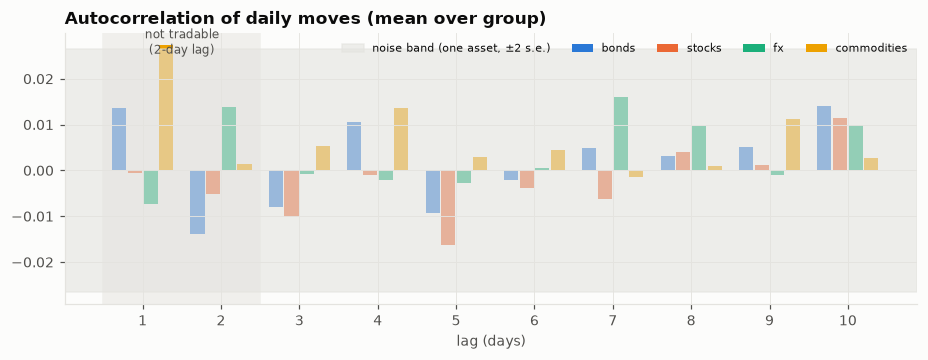

5-day reversion signal (minus past 5d move) -> next 5 days


,1995-02,2002-09,2009-16,full
group,,,,
bonds,-0.006,-0.037,0.013,-0.009
commodities,-0.036,-0.015,-0.014,-0.021
fx,-0.009,-0.030,-0.017,-0.019
stocks,0.029,0.019,0.021,0.022


In [10]:
# short-term reversion: autocorrelation of daily moves, lags 1-10 (lag 1-2 cannot be traded with the 2-day delay)
lags = range(1, 11)
ac = pd.DataFrame({g: [np.mean([z[a].autocorr(l) for a in cols]) for l in lags] for g, cols in GROUPS.items()}, index=lags)
band = 2 / np.sqrt(len(z))
fig, ax = plt.subplots(figsize=(10, 3.2))
w = 0.2
for i, g in enumerate(ac):
    ax.bar(np.array(list(lags)) + (i - 1.5) * w, ac[g], width=w * 0.9, color=C[i], label=g)
ax.axhspan(-band, band, color=GRID, alpha=0.6, label="noise band (one asset, ±2 s.e.)")
ax.axvspan(0.5, 2.5, color="#f0efec", zorder=-2)
ax.text(1.5, ax.get_ylim()[1] * 0.85, "not tradable\n(2-day lag)", ha="center", fontsize=8, color=INK2)
ax.set_xticks(list(lags)); ax.set_xlabel("lag (days)"); ax.legend(ncol=5, fontsize=7)
ax.set_title("Autocorrelation of daily moves (mean over group)")
plt.show()

rev = era_table(-MOM[5], 5, ORDER)
rev.insert(0, "group", pd.Series(GROUP))
print("5-day reversion signal (minus past 5d move) -> next 5 days")
display(rev.groupby("group")[list(ERAS) + ["full"]].mean().round(3))

**Takeaways**
- **Trend is real in every asset class.** The strongest cells are 60–250 day lookbacks predicting the next 20–60 days. With 12-month momentum, 25 of 27 assets have a positive IC (bonds 5/5, stocks 5/5, FX 3/4, commodities 12/13). That's the effect Jaakko's slow model harvests, and it confirms slow speeds.
- **Trend gets weaker over time.** 2009–16 is about zero for stocks, commodities and FX; only bonds keep trending. That's why Jaakko's scores fall 1.17 → 0.73 → 0.40. If the out-of-sample period looks like 2009–16, trend alone is a weak bet, which is the strongest argument for adding a second family.
- **Short-term reversion is essentially absent.** Daily autocorrelations sit inside the noise band. The only stable trace is a tiny 5-day reversion in stocks (IC ≈ 0.02 in every era), far too small to survive the 2-day lag and costs at a 5-day holding. **Don't spend people on short-term mean reversion.**

## 6. Relative value: twin assets and cross-moon spreads

If two assets share fundamentals, the gap between them should get pulled back. The **half-life** (from regressing the daily change of the spread on its level) says how fast. Tradeable needs roughly < 60 days; anything in the hundreds is just two separate trends.

twins (weekly corr > 0.8): [('antimatter', 'aerogel'), ('americium_ore', 'refined_americium'), ('beryllium', 'beryllium_monofilaments')]


,daily corr,half-life (days),IC spread z -> next 20d,1995-02,2002-09,2009-16
pair,,,,,,
io_stocks / titan_stocks,0.436,232.820,0.113,0.256,-0.034,0.122
callisto_stocks / europa_stocks,0.246,283.613,-0.041,-0.033,-0.055,-0.037
io_stocks / europa_stocks,0.709,402.940,0.083,-0.045,0.152,0.161
titan_stocks / europa_stocks,0.444,403.705,0.116,0.181,0.153,0.029
americium_ore / refined_americium,0.862,413.810,0.088,0.100,0.134,0.049
ganymede_stocks / europa_stocks,0.426,482.885,0.053,0.205,0.086,-0.097
io_stocks / callisto_stocks,0.247,488.468,0.066,-0.014,0.098,0.110
ganymede_stocks / callisto_stocks,0.162,517.465,-0.083,-0.182,0.094,-0.128
beryllium / beryllium_monofilaments,0.857,538.646,0.198,0.301,0.112,0.201


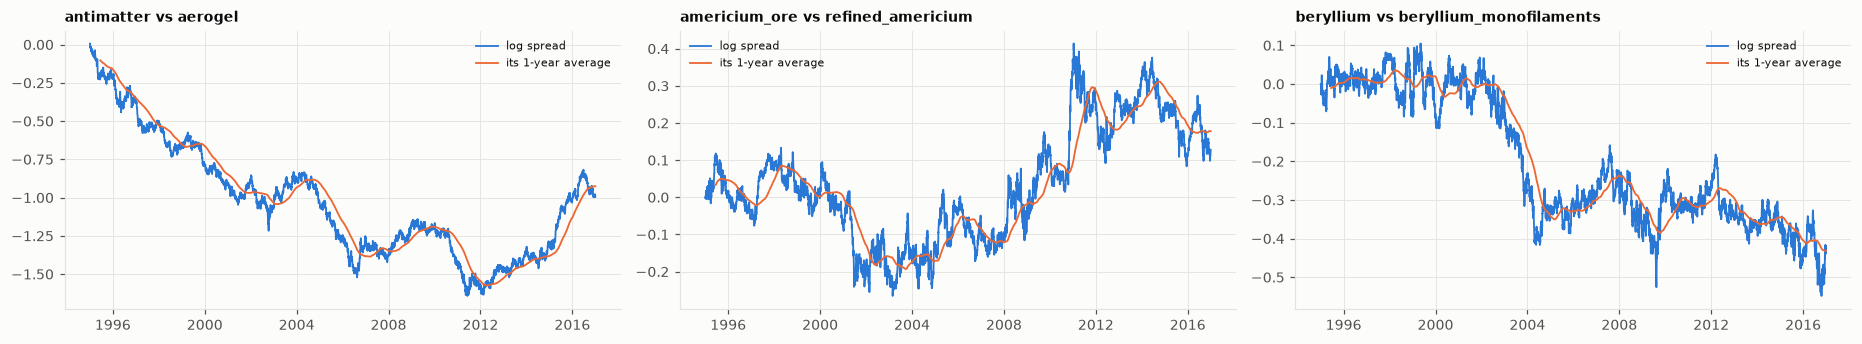

In [11]:
def half_life(s):
    s = s.dropna(); ds, lag = s.diff().iloc[1:], s.shift(1).iloc[1:]
    b = np.polyfit(lag, ds, 1)[0]
    return np.inf if b >= 0 else -np.log(2) / np.log(1 + b)

def spread(a, b):
    # vol-neutral log spread: hedge ratio from past data would be needed live; here a full-sample beta is only used to describe
    la, lb = np.log(px[a]), np.log(px[b])
    beta = np.polyfit(lb.diff().dropna(), la.diff().dropna(), 1)[0]
    return la - beta * lb

# twins = every pair with weekly correlation above 0.8 (a rule, not a hand pick)
TWINS = [tuple(ix) for ix, v in cw.where(np.triu(np.ones(cw.shape, bool), 1)).stack().items() if v > 0.8]
print("twins (weekly corr > 0.8):", TWINS)
pairs = list(TWINS)
for cls in ["bonds", "stocks"]:
    for i, a in enumerate(MOONS):
        for b in MOONS[i + 1:]:
            pairs.append((f"{a}_{cls}", f"{b}_{cls}"))

rows = []
for a, b in pairs:
    s = spread(a, b)
    zs = (s - s.rolling(250, min_periods=120).mean()) / s.rolling(250, min_periods=120).std()
    f = FWD[20][a] - FWD[20][b]                             # earnable move of long a / short b
    rows.append({"pair": f"{a} / {b}", "daily corr": z[a].corr(z[b]), "half-life (days)": half_life(s),
                 "IC spread z -> next 20d": us(-zs, f),
                 **{e: us(-zs.loc[s_:e_], f.loc[s_:e_]) for e, (s_, e_) in ERAS.items()}})
rv_tab = pd.DataFrame(rows).set_index("pair")
display(rv_tab.round(3).sort_values("half-life (days)"))

fig, axes = plt.subplots(1, len(TWINS), figsize=(17, 3.2))
for ax, (a, b) in zip(np.atleast_1d(axes), TWINS):
    s = spread(a, b)
    ax.plot(px.index, s, color=C[0], lw=1.2, label="log spread")
    ax.plot(px.index, s.rolling(250, min_periods=120).mean(), color=C[1], lw=1.2, label="its 1-year average")
    ax.set_title(f"{a} vs {b}", fontsize=9); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

**Takeaways**
- **Spreads don't return to a fixed level** (half-lives of hundreds of days), but **some revert toward their own 1-year average**, which is a different and tradable thing.
- **Pair by pair it's mixed, and that is the warning.** `beryllium` and `americium` twins revert in every era (IC 0.20 and 0.09). The third twin, `antimatter`/`aerogel`, does the **opposite**: its spread *trends* in every era (IC −0.14). Same structure, opposite behaviour, so the rule "twins revert" isn't universal.
- **Cross-moon spreads:** a few are stable (`callisto_bonds`/`europa_bonds` reverts, `io_bonds`/`titan_bonds` trends) but most flip sign between eras.
- **Verdict:** a small, real diversifier, but pair-specific. Picking only the pairs that worked would be in-sample selection. The fair test is a fixed rule (all three twins, decided by correlation alone), which section 10 runs. Kristofer can own this if he wants a relative-value angle.

## 7. Cross-asset lead-lag

Does asset A's past 5 days predict asset B's next 5 days? A 27 × 27 grid is 702 off-diagonal tests, so some will look strong by luck. The honest check: **does the grid from one era predict the grid in the next?** If lead-lag is real, the same pairs show up again.

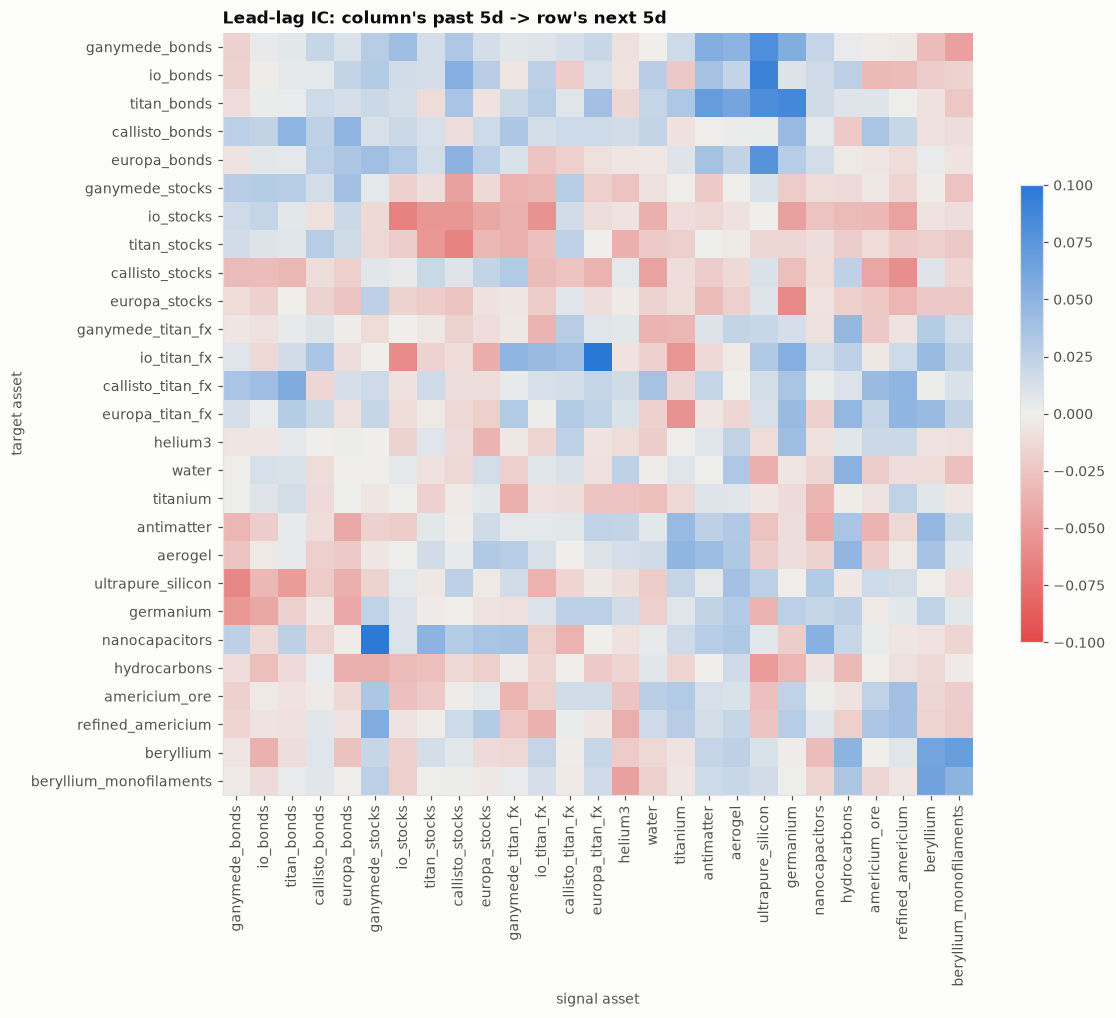

Does the lead-lag pattern repeat across eras? (correlation of the 702 off-diagonal cells)


,1995-02,2002-09,2009-16
1995-02,1.00,0.03,-0.02
2002-09,0.03,1.00,0.02
2009-16,-0.02,0.02,1.00


IC full  1995-02  2002-09  2009-16
titan_stocks      callisto_stocks     -0.064   -0.035   -0.112   -0.048
ultrapure_silicon ganymede_bonds      -0.061   -0.045   -0.010   -0.132
europa_stocks     germanium           -0.060   -0.103   -0.035   -0.045
io_titan_fx       io_stocks           -0.060   -0.078   -0.087   -0.021
callisto_stocks   refined_americium   -0.057   -0.074   -0.041   -0.058
titan_bonds       ultrapure_silicon    0.081    0.131    0.019    0.092
                  germanium            0.085    0.094    0.091    0.073
io_bonds          ultrapure_silicon    0.090    0.167   -0.003    0.106
nanocapacitors    ganymede_stocks      0.098    0.158    0.042    0.086
io_titan_fx       europa_titan_fx      0.101    0.087    0.106    0.109

noise level for one cell: ±0.059 (2 s.e.) -> with 702 cells expect ~35 beyond it by luck; observed 15


In [12]:
def ll_matrix(start=None, end=None):
    s, f = MOM[5].loc[start:end], FWD[5].loc[start:end]
    return pd.DataFrame({sig: uic(pd.DataFrame({t: s[sig] for t in ORDER}), f[ORDER]) for sig in ORDER}).loc[ORDER, ORDER]  # rows target, cols signal

LL = ll_matrix()
fig, ax = plt.subplots(figsize=(11, 9))
im = heat(ax, LL, "Lead-lag IC: column's past 5d -> row's next 5d", vmax=0.1, annot=False)
ax.set_xlabel("signal asset"); ax.set_ylabel("target asset")
fig.colorbar(im, ax=ax, shrink=0.6); plt.show()

eras_ll = {e: ll_matrix(s, en) for e, (s, en) in ERAS.items()}
off = ~np.eye(27, dtype=bool)
rep = pd.DataFrame({e1: {e2: np.corrcoef(eras_ll[e1].values[off], eras_ll[e2].values[off])[0, 1] for e2 in ERAS} for e1 in ERAS})
print("Does the lead-lag pattern repeat across eras? (correlation of the 702 off-diagonal cells)")
display(rep.round(2))

flat = LL.where(off).stack().dropna().sort_values()
top = pd.concat([flat.head(5), flat.tail(5)])
display(pd.DataFrame({"IC full": top, **{e: [eras_ll[e].loc[i, j] for i, j in top.index] for e in ERAS}}).round(3))
print(f"noise level for one cell: ±{2 / np.sqrt(len(px) / 5):.3f} (2 s.e.) -> with 702 cells expect ~35 beyond it by luck; "
      f"observed {(flat.abs() > 2 / np.sqrt(len(px) / 5)).sum()}")

**Takeaways**
- **The lead-lag grid is noise.** The pattern from one era has zero correlation with the next (all ≈ 0.0), and fewer cells pass the 2 s.e. line (15) than luck alone would produce (~35).
- A handful of top pairs keep their sign in every era (e.g. `europa_titan_fx` → `io_titan_fx`, `germanium` → `titan_bonds`), but they're the best few of 702 draws, with no story.
- **Verdict: drop.**

## 8. Macro: do GDP and CPI move the moon's own assets?

Macro dated day T is known at the end of T, the same as prices. Calendar days are mapped to trading days with the **last value at or before T**, so a weekend print is used on Monday, never earlier.

Features: growth over *k* days of log GDP and log CPI (k = 5…250; k = 250 ≈ annual growth and annual inflation). Each moon's macro is tested against **that moon's** bonds, stocks and FX.

daily change autocorrelation (smoothness): {'gdp|ganymede': 0.26, 'gdp|io': 0.52, 'gdp|titan': 0.56, 'gdp|callisto': 0.44, 'gdp|europa': 0.48, 'cpi|ganymede': 0.19, 'cpi|io': 0.14, 'cpi|titan': 0.19, 'cpi|callisto': 0.21, 'cpi|europa': 0.15}


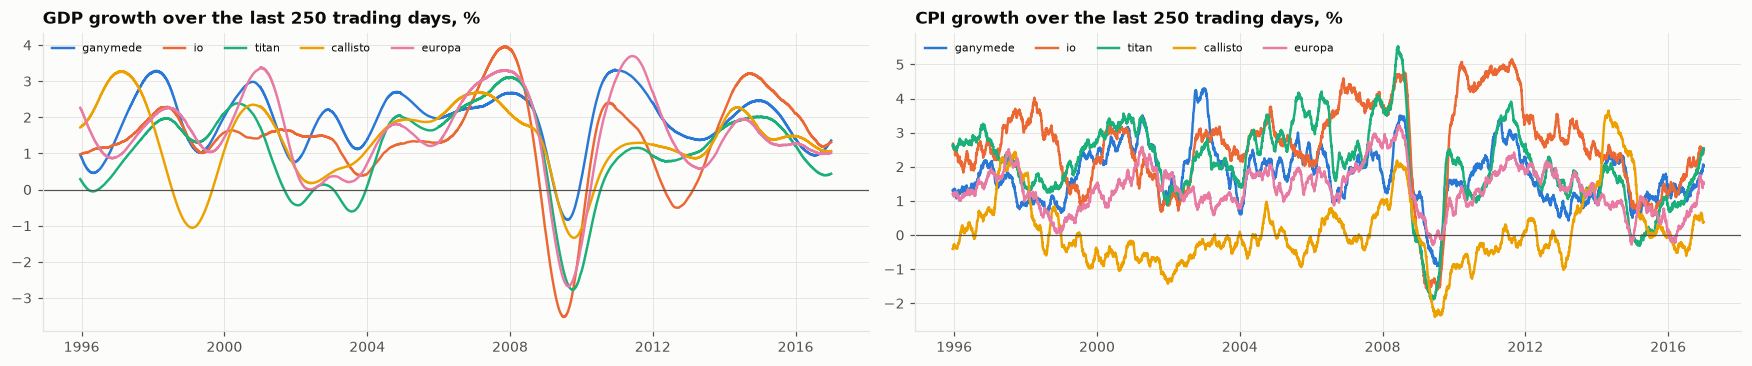

In [13]:
mac = np.log(macro.reindex(macro.index.union(px.index)).ffill().reindex(px.index))
dm = mac.diff()
print("daily change autocorrelation (smoothness):", dm.apply(lambda s: s.autocorr()).round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(16, 3.4))
for ax, m in zip(axes, ["gdp", "cpi"]):
    for i, mo in enumerate(MOONS):
        ax.plot(mac.index, mac[f"{m}|{mo}"].diff(250) * 100, color=C[i], label=mo)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_title(f"{m.upper()} growth over the last 250 trading days, %"); ax.legend(ncol=5, fontsize=7)
fig.tight_layout(); plt.show()

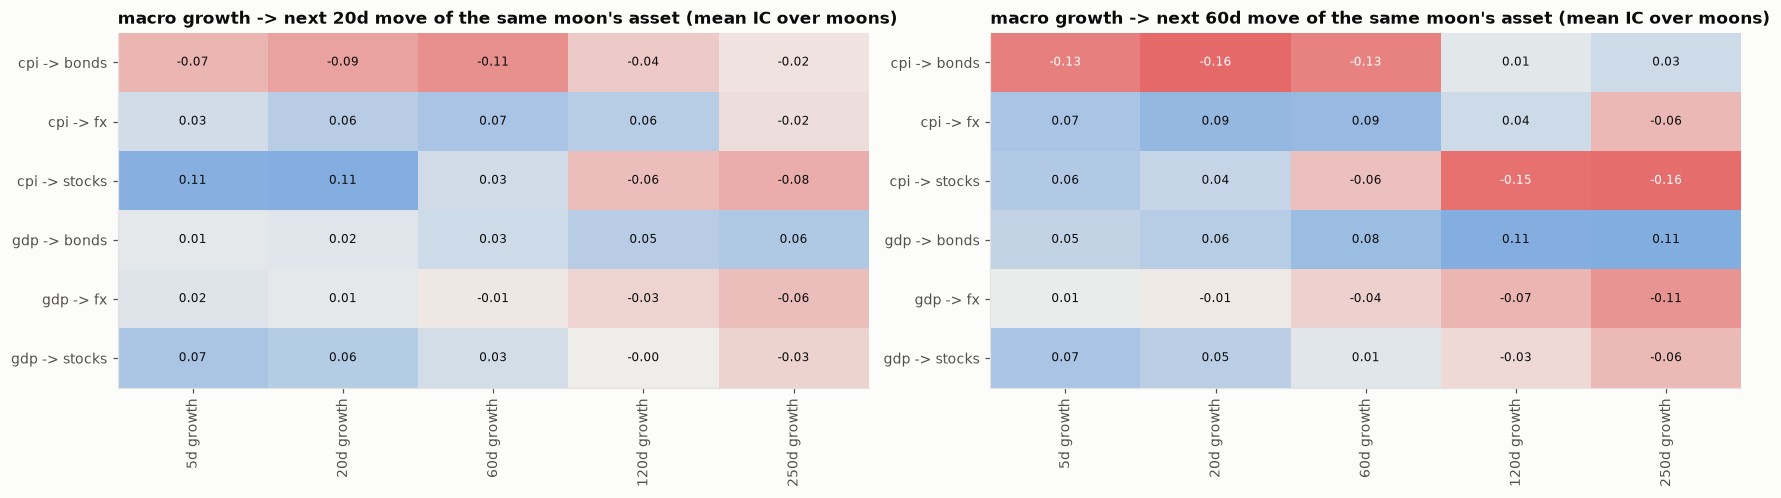

Cells that pass the stability rule (same sign in all 3 eras, all or all-but-one moons agree):


full  1995-02  2002-09  2009-16  moons_same_sign  t per moon
macro target k   h                                                                
cpi   bonds  20  60 -0.160   -0.059   -0.275   -0.105                5      -1.555
      stocks 250 60 -0.156   -0.110   -0.144   -0.224                5      -1.519
             120 60 -0.151   -0.148   -0.159   -0.168                5      -1.472
      bonds  5   60 -0.133   -0.032   -0.236   -0.104                5      -1.296
             60  60 -0.130   -0.090   -0.227   -0.037                5      -1.268
                 20 -0.113   -0.025   -0.207   -0.067                5      -1.910
      stocks 20  20  0.109    0.101    0.101    0.126                5       1.844
gdp   fx     250 60 -0.108   -0.111   -0.039   -0.120                4      -1.053
cpi   stocks 5   20  0.106    0.078    0.103    0.130                5       1.786
      fx     20  60  0.092    0.021    0.099    0.108                4       0.895
             60  60  0.088    0.031    0.102    0.099                3       0.860
      stocks 250 20 -0.079   -0.049   -0.086   -0.102                5      -1.338
      fx     5   60  0.072    0.013    0.081    0.080                4       0.700
             60  20  0.072    0.015    0.076    0.091                4       1.208
      stocks 5   60  0.064    0.066    0.057    0.060                5       0.623
gdp   fx     250 20 -0.059   -0.062   -0.008   -0.065                4      -1.000
cpi   stocks 120 20 -0.059   -0.069   -0.095   -0.029                5      -0.990
      fx     120 20  0.057    0.014    0.102    0.044                4       0.970
      stocks 60  60 -0.055   -0.007   -0.074   -0.085                5      -0.541
             20  60  0.043    0.075    0.027    0.022                5       0.420

In [14]:
KM = [5, 20, 60, 120, 250]

def mfeat(k, win=750):
    # macro growth over k days minus its own trailing 3-year average (past data only).
    # GDP growth is almost always positive, so raw growth would just mean 'always long'; the
    # question is whether growth ABOVE its recent normal predicts anything.
    g = mac.diff(k)
    return g - g.rolling(win, min_periods=250).mean()

rows = []
for m in ["gdp", "cpi"]:
    for k in KM:
        feat = mfeat(k)
        for cls, lab in [("bonds", "bonds"), ("stocks", "stocks"), ("titan_fx", "fx")]:
            for h in [20, 60]:
                for mo in MOONS:
                    a = f"{mo}_{cls}"
                    if a not in px:
                        continue
                    s = feat[f"{m}|{mo}"]
                    r = {"macro": m, "k": k, "target": lab, "h": h, "moon": mo, "full": us(s, FWD[h][a])}
                    for e, (s_, e_) in ERAS.items():
                        r[e] = us(s.loc[s_:e_], FWD[h][a].loc[s_:e_])
                    rows.append(r)
MAC = pd.DataFrame(rows)

agg = MAC.groupby(["macro", "target", "k", "h"]).agg(
    full=("full", "mean"), **{e: (e, "mean") for e in ERAS},
    moons_same_sign=("full", lambda s: int(max((s > 0).sum(), (s < 0).sum()))), n=("full", "size"))
agg["stable"] = (np.sign(agg[list(ERAS)]).nunique(axis=1) == 1) & (agg["moons_same_sign"] >= agg["n"] - 1)
agg["t per moon"] = tstat(agg["full"], agg.index.get_level_values("h"))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
for ax, h in zip(axes, [20, 60]):
    t = agg.xs(h, level="h")["full"].unstack("k")
    t.index = [f"{m} -> {tg}" for m, tg in t.index]
    t.columns = [f"{k}d growth" for k in t.columns]
    heat(ax, t, f"macro growth -> next {h}d move of the same moon's asset (mean IC over moons)", vmax=0.2, fontsize=8)
fig.tight_layout(); plt.show()

print("Cells that pass the stability rule (same sign in all 3 eras, all or all-but-one moons agree):")
display(agg[agg["stable"]].sort_values("full", key=np.abs, ascending=False)
        .drop(columns=["stable", "n"]).round(3).head(20))

In [15]:
# per moon detail for the strongest candidates
cand = [("cpi", 20, "bonds", 60), ("cpi", 60, "bonds", 60), ("cpi", 120, "stocks", 60),
        ("cpi", 250, "stocks", 60), ("gdp", 250, "stocks", 60), ("gdp", 120, "bonds", 60)]
det = MAC.set_index(["macro", "k", "target", "h"]).loc[cand].reset_index()
det["rule"] = det["macro"] + " " + det["k"].astype(str) + "d -> " + det["target"] + " next " + det["h"].astype(str) + "d"
display(det.pivot(index="rule", columns="moon", values="full")[MOONS].round(3)
        .style.background_gradient(cmap=DIV, vmin=-0.3, vmax=0.3).format(precision=3))

moon,ganymede,io,titan,callisto,europa
rule,,,,,
cpi 120d -> stocks next 60d,-0.207,-0.123,-0.123,-0.143,-0.160
cpi 20d -> bonds next 60d,-0.215,-0.182,-0.207,-0.053,-0.141
cpi 250d -> stocks next 60d,-0.136,-0.123,-0.253,-0.061,-0.205
cpi 60d -> bonds next 60d,-0.181,-0.103,-0.114,-0.074,-0.178
gdp 120d -> bonds next 60d,0.247,0.085,0.104,0.039,0.072
gdp 250d -> stocks next 60d,-0.049,-0.112,-0.005,-0.061,-0.087


In [16]:
# timing: is the macro already priced, or does the market lead the macro?
def xcorr(a_series, b_series):
    return us(a_series, b_series)

tim = []
for m in ["gdp", "cpi"]:
    for cls in ["bonds", "stocks"]:
        for mo in MOONS:
            a = f"{mo}_{cls}"
            ret60 = (px[a] - px[a].shift(60)) / (vol[a] * np.sqrt(60))
            g60 = mfeat(60)[f"{m}|{mo}"]
            tim.append({"pair": f"{m} vs {cls}", "moon": mo,
                        "macro leads price (past macro -> next price)": xcorr(g60, FWD[60][a]),
                        "same window": xcorr(g60, ret60),
                        "price leads macro (past price -> next macro)": xcorr(ret60, g60.shift(-60))})
tim = pd.DataFrame(tim).groupby("pair").mean(numeric_only=True)
display(tim.round(3))

,macro leads price (past macro -> next price),same window,price leads macro (past price -> next macro)
pair,,,
cpi vs bonds,-0.130,-0.158,0.021
cpi vs stocks,-0.055,0.188,0.091
gdp vs bonds,0.083,-0.011,-0.089
gdp vs stocks,0.015,0.159,0.310


In [17]:
# relative macro vs FX: moon growth/inflation minus titan's, against the moon's FX vs titan
rows = []
for m in ["gdp", "cpi"]:
    for k in [20, 60, 250]:
        r = {"feature": f"{m} {k}d, moon minus titan"}
        for mo in [x for x in MOONS if x != "titan"]:
            f = mfeat(k)[f"{m}|{mo}"] - mfeat(k)[f"{m}|titan"]
            r[mo] = xcorr(f, FWD[60][f"{mo}_titan_fx"])
        rows.append(r)
display(pd.DataFrame(rows).set_index("feature").round(3))

,ganymede,io,callisto,europa
feature,,,,
"gdp 20d, moon minus titan",-0.047,0.112,-0.005,0.122
"gdp 60d, moon minus titan",-0.037,0.095,-0.013,0.096
"gdp 250d, moon minus titan",0.014,0.072,-0.047,0.024
"cpi 20d, moon minus titan",-0.135,-0.098,0.064,-0.069
"cpi 60d, moon minus titan",-0.159,-0.062,-0.005,-0.048
"cpi 250d, moon minus titan",0.018,0.150,-0.098,0.277


**Takeaways**
- **Inflation is the planted edge.** The strongest, most stable cells are all CPI: ICs of **0.11–0.16 at a 60-day horizon**, same sign in all three eras and **all five moons**. That's as strong as 12-month trend, and it's a different mechanism.
- **Inflation → bonds (negative), the cleanest story.** When a moon's CPI has risen faster than its recent normal over the last 5–60 days, its bonds fall over the next 20–60 days. Economics: rising inflation → the central bank hikes rates → bond prices drop.
- **Inflation → stocks has two speeds.** A short burst of inflation (5–20 days) goes with *rising* stocks over the next 20 days (nominal growth, pricing power). Persistent inflation (120–250 days) predicts *falling* stocks over the next 60 days (higher discount rates, margin squeeze). **Use the slow measure for a stock rule**; the fast one is weaker and fights it.
- **GDP is mostly not useful.** Done causally, GDP → stocks is about zero, and the timing table shows why: stock prices **lead** GDP (IC 0.31), so growth news is already priced. GDP → bonds looks positive in the heatmap (0.11) but fails the era and moon stability rule. The only stable GDP cell is annual growth vs FX (negative, 4 of 4 moons).
- **FX:** relative inflation vs titan gives mixed signs across moons. Low priority.
- **Caveat:** 60 macro cells × 5 moons is many tests. Trust only the cells that pass the "all eras, (almost) all moons" rule, and lead the pitch with the economic story, not the number.

## 9. Price bars (Open/High/Low/Close): anything extra?

In [18]:
O, H, L, CL = (bars[[f"{a}|{f}" for a in px]].set_axis(list(px), axis=1) for f in ["Open", "High", "Low", "Close"])
clv = ((CL - L) - (H - CL)) / (H - L)                       # where the close sits in the day's range, -1..1
gap = (O - CL.shift(1)) / vol.shift(1)                     # overnight move
intra = (CL - O) / vol.shift(1)                            # open -> close
ob = pd.DataFrame({name: [ic(sig, h).mean() for h in [1, 5, 20]] for name, sig in
                   {"close location in range": clv, "overnight gap": gap, "intraday move": intra}.items()},
                  index=["next 1d", "next 5d", "next 20d"]).T
display(ob.round(4))
print("bar consistency violations (High below Open/Close or Low above):",
      int((H < np.maximum(O, CL) - 1e-12).sum().sum() + (L > np.minimum(O, CL) + 1e-12).sum().sum()))

,next 1d,next 5d,next 20d
close location in range,-7.400e-03,-0.003,0.009
overnight gap,-1.000e-03,-0.004,0.005
intraday move,-2.000e-04,0.005,0.011


bar consistency violations (High below Open/Close or Low above): 0


**Takeaway:** bar features carry no predictive information (ICs ≈ 0). Their only use is a slightly better **volatility estimate** (high-low range), and section 4 showed vol is nearly constant anyway. **Ignore OHLC.**

## 10. Sanity check: does the IC turn into P&L?

Not a strategy search: one fixed, untuned rule per family, all through the **same** sizing (forecast / vol, book scaled to constant risk, 30% daily glide) and Lynx's evaluator. The point is the sign, the order of magnitude, and **how correlated each family is with trend**.

Note the macro rules were chosen after looking at section 8, so their score here is in-sample; the era columns are what to look at.

In [19]:
def zscore(x, win=750):
    return x / x.rolling(win, min_periods=250).std()

def adj_sharpe(r):
    from scipy import stats
    r = r.dropna(); sr = r.mean() / r.std() * np.sqrt(260)
    return sr * (1 + sr / 6 * stats.skew(r, bias=False) - sr ** 2 / 24 * stats.kurtosis(r, bias=False))

def book(f, alpha=0.3, win=250):
    units = (f / vol).replace([np.inf, -np.inf], np.nan).fillna(0.0)
    live = units.abs().sum(axis=1) > 0
    pnl = (units.shift(2) * d).sum(axis=1).where(live.shift(2, fill_value=False))   # risk measured only once the book is on
    pos = units.div(pnl.rolling(win, min_periods=60).std(), axis=0)
    return pos.ewm(alpha=alpha, adjust=False).mean().replace([np.inf, -np.inf], np.nan).fillna(0.0)

def to_pl(pos):
    pos = pos.copy(); pos.index.name = "AsOfDate"
    return pl.from_pandas(pos.reset_index()).with_columns(pl.col("AsOfDate").cast(pl.Date))

PL_PX = to_pl(px)
empty = pd.DataFrame(0.0, index=px.index, columns=px.columns)

def bonds_cpi():
    f = empty.copy()
    for mo in MOONS:
        f[f"{mo}_bonds"] = -np.tanh(zscore(mfeat(60)[f"cpi|{mo}"]))
    return f

def stocks_cpi():
    f = empty.copy()
    for mo in MOONS:
        f[f"{mo}_stocks"] = -np.tanh(zscore(mfeat(120)[f"cpi|{mo}"]))
    return f

def twins():
    f = empty.copy()
    for a, b in TWINS:
        s = np.log(px[a]) - np.log(px[b])
        zs = (s - s.rolling(250, min_periods=120).mean()) / s.rolling(250, min_periods=120).std()
        f[a], f[b] = -np.tanh(zs / 2), np.tanh(zs / 2)
    return f

FAM = {
    "trend: 12m momentum, all assets": np.tanh(MOM[250]),
    "macro: CPI 60d -> short bonds": bonds_cpi(),
    "macro: CPI 120d -> short stocks": stocks_cpi(),
    "relative value: twin spreads": twins(),
}
FAM["macro: both rules"] = FAM["macro: CPI 60d -> short bonds"] + FAM["macro: CPI 120d -> short stocks"]

POS, RET, rows = {}, {}, []
for name, f in FAM.items():
    pos = book(f.fillna(0.0))
    kf = ev.calc_key_figures(to_pl(pos), PL_PX, key_figures=["adjusted_sharpe", "sharpe", "av_holding", "returns"])
    r = kf["returns"].to_pandas().set_index("AsOfDate")["returns"]
    POS[name], RET[name] = pos, r
    row = {"family": name, "adj sharpe": kf["adjusted_sharpe"], "sharpe": kf["sharpe"], "holding d": kf["av_holding"]}
    row["skew"], row["kurtosis"] = r.skew(), r.kurt() + 3
    for e, (s, en) in ERAS.items():
        x = r.loc[s:en].dropna(); row[e] = x.mean() / x.std() * np.sqrt(260)
    rows.append(row)

# 50/50 risk blend of trend and the macro book
ret = pd.DataFrame(RET)
blend = ret["trend: 12m momentum, all assets"] / ret["trend: 12m momentum, all assets"].std() \
      + ret["macro: both rules"] / ret["macro: both rules"].std()
row = {"family": "50/50 risk blend: trend + macro", "adj sharpe": adj_sharpe(blend), "sharpe": blend.mean() / blend.std() * np.sqrt(260)}
for e, (s, en) in ERAS.items():
    x = blend.loc[s:en].dropna(); row[e] = x.mean() / x.std() * np.sqrt(260)
rows.append(row)
def blend_row(name, parts):
    b = sum(ret[p] / ret[p].std() for p in parts)
    row = {"family": name, "adj sharpe": adj_sharpe(b), "sharpe": b.mean() / b.std() * np.sqrt(260),
           "skew": b.skew(), "kurtosis": b.kurt() + 3}
    for e, (s, en) in ERAS.items():
        x = b.loc[s:en].dropna(); row[e] = x.mean() / x.std() * np.sqrt(260)
    return row, b

rows = rows[:-1]
TR, MC, TW = "trend: 12m momentum, all assets", "macro: both rules", "relative value: twin spreads"
r2, blend = blend_row("equal-risk blend: trend + macro", [TR, MC])
r3, blend3 = blend_row("equal-risk blend: trend + macro + twins", [TR, MC, TW])
rows += [r2, r3]
display(pd.DataFrame(rows).set_index("family").round(2))
print("P&L correlation between families:")
display(ret.corr().round(2))

,adj sharpe,sharpe,holding d,skew,kurtosis,1995-02,2002-09,2009-16
family,,,,,,,,
"trend: 12m momentum, all assets",0.87,0.99,58.14,-0.08,5.50,1.89,0.87,0.38
macro: CPI 60d -> short bonds,0.51,0.54,47.39,0.35,9.62,0.15,0.98,0.44
macro: CPI 120d -> short stocks,0.28,0.29,63.88,-0.01,9.00,0.15,0.65,0.07
relative value: twin spreads,0.30,0.31,33.68,-0.18,5.15,0.23,0.42,0.28
macro: both rules,0.65,0.70,55.88,-0.02,6.36,0.33,1.29,0.45
equal-risk blend: trend + macro,0.96,1.22,NaN,-0.10,6.06,1.55,1.60,0.61
equal-risk blend: trend + macro + twins,1.02,1.17,NaN,-0.08,4.97,1.39,1.56,0.65


P&L correlation between families:


,"trend: 12m momentum, all assets",macro: CPI 60d -> short bonds,macro: CPI 120d -> short stocks,relative value: twin spreads,macro: both rules
"trend: 12m momentum, all assets",1.00,0.05,-0.11,-0.02,-0.04
macro: CPI 60d -> short bonds,0.05,1.00,-0.22,-0.01,0.61
macro: CPI 120d -> short stocks,-0.11,-0.22,1.00,0.03,0.61
relative value: twin spreads,-0.02,-0.01,0.03,1.00,0.02
macro: both rules,-0.04,0.61,0.61,0.02,1.00


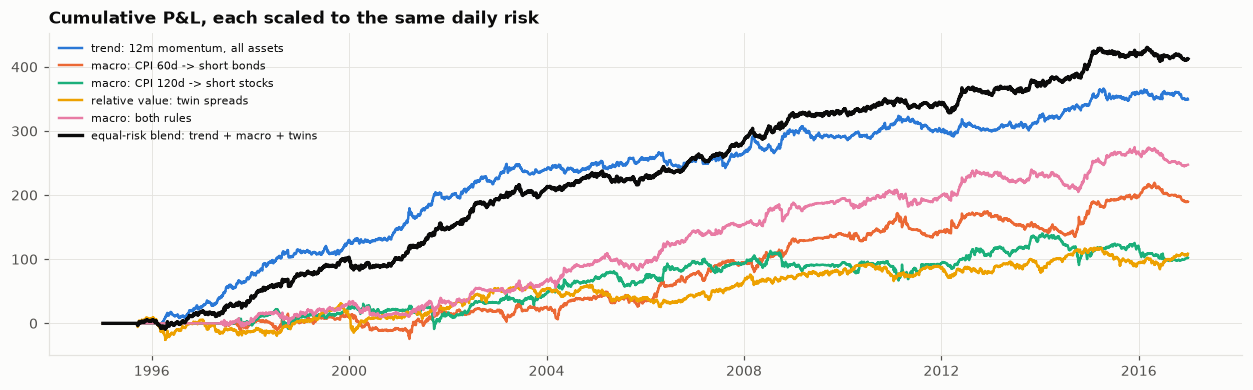

In [20]:
fig, ax = plt.subplots(figsize=(14, 3.8))
for i, (name, r) in enumerate(RET.items()):
    ax.plot(r.index, (r / r.std()).cumsum(), color=C[i], label=name)
ax.plot(blend3.index, (blend3 / blend3.std()).cumsum(), color=INK, lw=2.2, label="equal-risk blend: trend + macro + twins")
ax.set_title("Cumulative P&L, each scaled to the same daily risk"); ax.legend(fontsize=7.5)
plt.show()

**Takeaways**
- **The ICs do turn into money**, with untuned rules: 12-month trend 0.87 adjusted Sharpe, inflation → bonds 0.51, both inflation rules together 0.65, rule-based twin spreads 0.30.
- **The families are uncorrelated** (P&L correlations between −0.1 and +0.05). That's the whole case for combining them.
- **The blend beats every part:** trend + macro 0.96, trend + macro + twins **1.02**, and it's positive in all three eras. In 2009–16, where trend alone falls to 0.38, the blend holds 0.65.
- These are first-look numbers, not a final model: no speed choice, no per-moon checks, the macro rules were chosen after looking at section 8, and the blend is a simple sum of returns rather than one portfolio. The next step is to build them properly through the shared pipeline and the harness (`validate.py`).

## 11. Scoreboard and next steps

| Family | Exists? | Strength | Stable across eras | Story | Verdict |
|---|---|---|---|---|---|
| **Macro: inflation → bonds** | **Yes** | IC 0.11–0.16 at 20–60d; toy rule 0.51 | **Yes, all 5 moons** | Inflation → rate hikes → bond prices fall | **Main new signal. Build it properly.** |
| **Macro: slow inflation → stocks** | Yes | IC 0.15 at 60d; toy rule 0.28 | Yes, all 5 moons | Discount rates up, margins squeezed | **Second macro rule**, test together with the bond rule |
| **Trend (60–250d)** | Yes | IC up to 0.17; toy rule 0.87 | Yes, but fading in 2009–16 | Slow reaction, herding | **Keep Jaakko's slow model.** Don't tune it further. |
| Twin spreads vs 1-year average | Partly | toy rule 0.30 | Pair-specific (one twin trends) | Same fundamentals | Small diversifier, optional |
| Macro: GDP | Mostly no | ≈ 0 once causal | | Stocks price GDP early | Drop, except maybe annual GDP → FX |
| Macro: relative inflation → FX | Weak | mixed signs | No | Rate differentials | Low priority |
| Short-term reversion | No | ≈ 0.02 | Tiny | | **Drop** |
| Cross-asset lead-lag | No | noise | Era repeat ≈ 0 | | **Drop** |
| OHLC bar features | No | ≈ 0 | | | **Drop** |
| Vol timing | No | vol barely clusters | | | Use a long, stable vol estimate |

### What each person does next
1. **Macro (Erik):** turn the stable section 8 cells into one inflation forecast per moon: fast inflation (5–60 days, vs its trailing normal) against bonds, slow inflation (120–250 days) against stocks. Check every moon separately, and look for a plateau of good lookbacks, not one peak.
2. **Trend (Jaakko):** keep the slow EWMAC + 12-month blend as is. Own the shared pipeline (sizing, book risk, glide) so the macro and twin forecasts plug straight in.
3. **Relative value and risk (Kristofer):** twin spreads with a fixed rule, plus the risk overlay: one budget per twin pair, a cap on the bond block, and a smaller budget for fat-tailed `ultrapure_silicon`.
4. **Validation and combination (Eemil):** combine trend + macro (+ twins) in one portfolio, score it in all three eras with `validate.py`, run the leak test, and own the pitch: *trend for what trends, inflation for what cares about inflation, and they don't overlap.*